<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory — Chapter Visualizations
**PSE Lab | SeoulTech**

This notebook provides **8 interactive visualizations** corresponding to the eight chapters of the Gauge Theory course (Tong, Cambridge).

| # | Visualization | Chapter |
|---|---|---|
| 1 | Dirac Quantisation & Monopole Field | Ch 1: Electromagnetism |
| 2 | Instanton Action & Theta Vacuum Energy | Ch 2: Yang-Mills |
| 3 | Chiral Anomaly: Chirality Production in E·B Fields | Ch 3: Anomalies |
| 4 | Lattice Strong-Coupling Expansion & Wilson Loop | Ch 4: Lattice Gauge Theory |
| 5 | Chiral Condensate & GOR Relation | Ch 5: Chiral Symmetry Breaking |
| 6 | Large N Scaling of Widths & Witten-Veneziano | Ch 6: Large N |
| 7 | Bosonisation: Sine-Gordon Kink & MT–SG Duality Map | Ch 7: 2D QFT |
| 8 | Chern-Simons: Hall Conductance & Anyon Statistics | Ch 8: 3D QFT |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch
from matplotlib.colors import LogNorm
from scipy.special import gamma
import warnings
warnings.filterwarnings('ignore')

# ── Consistent dark style (amber accent) ──────────────────────────────────
BG    = '#0d1117'
SURF  = '#161b22'
EDGE  = '#30363d'
TEXT  = '#e6edf3'
DIM   = '#8b949e'
AMBER = '#e8a838'
BLUE  = '#7ec8e3'
GREEN = '#90ee90'
RED   = '#e07070'
PURP  = '#c792ea'
YELL  = '#f9c74f'
ORAN  = '#ffa657'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': SURF,
    'axes.edgecolor': EDGE, 'axes.labelcolor': TEXT,
    'xtick.color': DIM, 'ytick.color': DIM,
    'text.color': TEXT, 'grid.color': EDGE,
    'grid.alpha': 0.35, 'lines.linewidth': 2.2,
    'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMBER, 'figure.dpi': 110,
    'legend.framealpha': 0.3, 'legend.edgecolor': EDGE,
})
print('Setup complete — Gauge Theory visualizations ready.')

Setup complete — Gauge Theory visualizations ready.


---
## Visualization 1 · Dirac Quantisation & Monopole Field (Ch 1)

The magnetic monopole of charge $g$ produces a radial field $\mathbf{B}=g\hat{r}/4\pi r^2$.
The Dirac condition $eg=2\pi n$ arises from single-valuedness of the wavefunction.
Here we visualise: **(a)** the flux through $S^2$, **(b)** the Dirac string potential on the two patches,
**(c)** the quantised charge spectrum $(n, Q_e)$ with theta angle.

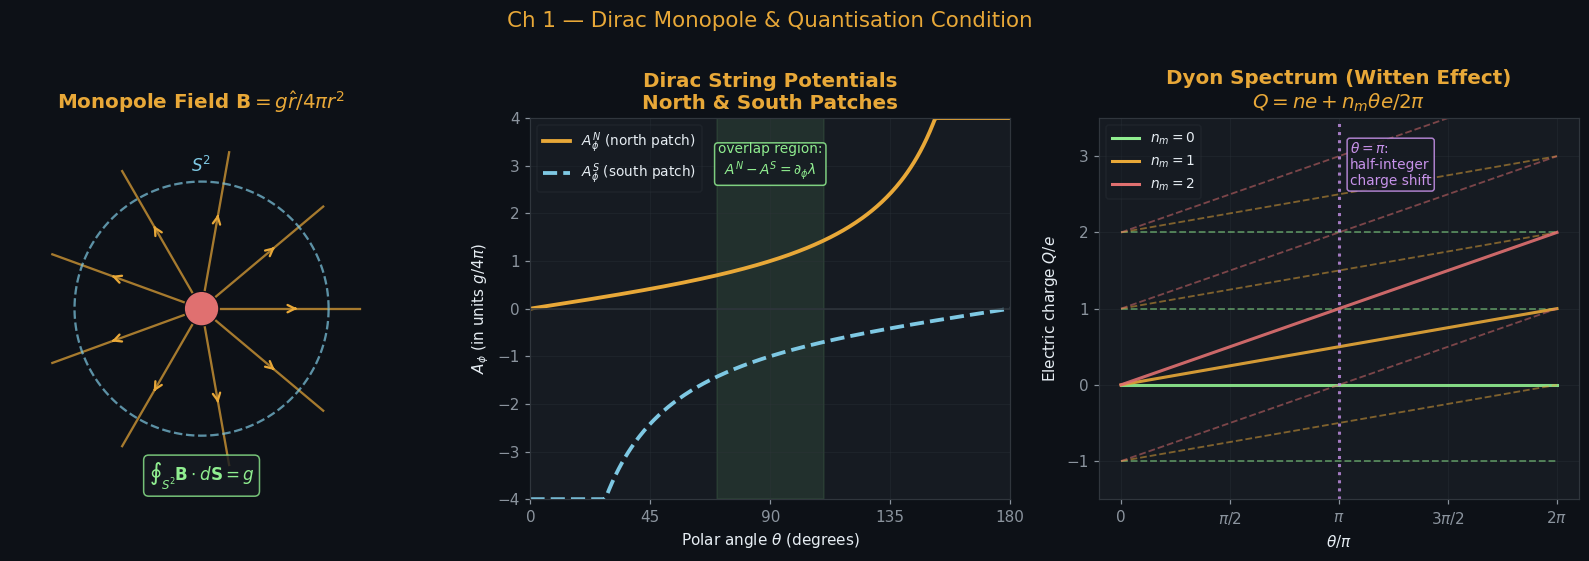

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Ch 1 — Dirac Monopole & Quantisation Condition', color=AMBER, fontsize=14, y=1.01)

# ── Left: Monopole B-field lines (2D cross-section) ──────────────────────
ax = axes[0]
theta_arr = np.linspace(0, 2*np.pi, 9, endpoint=False)
r_arr = np.linspace(0.3, 2.5, 50)
for th in theta_arr:
    x_line = r_arr * np.cos(th)
    y_line = r_arr * np.sin(th)
    ax.plot(x_line, y_line, color=AMBER, alpha=0.7, lw=1.5)
    # Arrowhead
    i_mid = len(r_arr)//2
    ax.annotate('', xy=(x_line[i_mid+3], y_line[i_mid+3]),
                xytext=(x_line[i_mid], y_line[i_mid]),
                arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.5, mutation_scale=12))

# Monopole at centre
circ = Circle((0, 0), 0.25, color=RED, zorder=5)
ax.add_patch(circ)
ax.text(0, 0, '$g$', ha='center', va='center', fontsize=13, color='white', fontweight='bold')

# S^2 sphere
th_s = np.linspace(0, 2*np.pi, 200)
ax.plot(2.0*np.cos(th_s), 2.0*np.sin(th_s), color=BLUE, lw=1.5, ls='--', alpha=0.7)
ax.text(0, 2.15, r'$S^2$', ha='center', color=BLUE, fontsize=11)

# Flux label
ax.text(0, -2.7, r'$\oint_{S^2}\mathbf{B}\cdot d\mathbf{S} = g$',
        ha='center', fontsize=11, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.3', facecolor=SURF, edgecolor=GREEN, alpha=0.8))
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_aspect('equal'); ax.axis('off')
ax.set_title(r'Monopole Field $\mathbf{B}=g\hat{r}/4\pi r^2$')

# ── Middle: Gauge potential on two patches ────────────────────────────────
ax2 = axes[1]
theta_lat = np.linspace(0, np.pi, 300)
# Northern patch: A^N_phi = g(1-cos theta)/(4pi sin theta)
A_N = (1 - np.cos(theta_lat)) / (np.sin(theta_lat) + 1e-10)
# Southern patch: A^S_phi = -g(1+cos theta)/(4pi sin theta)
A_S = -(1 + np.cos(theta_lat)) / (np.sin(theta_lat) + 1e-10)

# Clip for display
A_N_disp = np.clip(A_N, -4, 4)
A_S_disp = np.clip(A_S, -4, 4)

ax2.plot(np.degrees(theta_lat), A_N_disp, color=AMBER, lw=2.5, label=r'$A^N_\phi$ (north patch)')
ax2.plot(np.degrees(theta_lat), A_S_disp, color=BLUE, lw=2.5, ls='--', label=r'$A^S_\phi$ (south patch)')

# Overlap region
ax2.axvspan(70, 110, color=GREEN, alpha=0.10)
ax2.text(90, 3.5, 'overlap region:\n'+r'$A^N-A^S=\partial_\phi\lambda$', ha='center', fontsize=9, color=GREEN, va='top', bbox=dict(boxstyle='round,pad=0.25', facecolor=SURF, edgecolor=GREEN, alpha=0.85))

ax2.axhline(0, color=EDGE, lw=1)
ax2.set_xlabel(r'Polar angle $\theta$ (degrees)')
ax2.set_ylabel(r'$A_\phi$ (in units $g/4\pi$)')
ax2.set_title('Dirac String Potentials\nNorth & South Patches')
ax2.legend(fontsize=9, labelcolor=TEXT)
ax2.set_xlim(0, 180); ax2.set_ylim(-4, 4)
ax2.set_xticks([0, 45, 90, 135, 180])
ax2.grid(True, alpha=0.3)

# ── Right: Dyon spectrum Q = ne + n_m * theta*e / 2pi ─────────────────────
ax3 = axes[2]
theta_vals = np.linspace(0, 2*np.pi, 300)
n_mag_vals = [0, 1, 2]
colors_nm = [GREEN, AMBER, RED]

for n_m, col in zip(n_mag_vals, colors_nm):
    for n_e in range(-1, 3):
        Q = n_e + n_m * theta_vals / (2*np.pi)
        ax3.plot(theta_vals/np.pi, Q, color=col,
                 lw=2.0 if n_e == 0 else 1.2,
                 ls='-' if n_e == 0 else '--',
                 alpha=0.9 if n_e == 0 else 0.5)

# Legend
from matplotlib.lines import Line2D
leg = [Line2D([0],[0], color=c, lw=2, label=f'$n_m={n}$')
       for n,c in zip(n_mag_vals, colors_nm)]
ax3.legend(handles=leg, fontsize=9, labelcolor=TEXT)

ax3.axvline(1, color=PURP, lw=2, ls=':', alpha=0.8)
ax3.text(1.05, 3.2, r'$\theta=\pi$:'+chr(10)+'half-integer'+chr(10)+'charge shift', fontsize=9, color=PURP, va='top', bbox=dict(boxstyle='round,pad=0.2', facecolor=SURF, edgecolor=PURP, alpha=0.85))

ax3.set_xlabel(r'$\theta/\pi$')
ax3.set_ylabel(r'Electric charge $Q/e$')
ax3.set_title('Dyon Spectrum (Witten Effect)\n'+r'$Q = ne + n_m\theta e/2\pi$')
ax3.set_xticks([0, 0.5, 1, 1.5, 2])
ax3.set_xticklabels(['0', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
ax3.set_ylim(-1.5, 3.5)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Visualization 2 · Instanton Action & Theta Vacuum (Ch 2)

The BPST instanton saturates the BPS bound $S\ge 8\pi^2|k|/g^2$.
The theta vacuum $|\theta\rangle$ has energy $\mathcal{E}(\theta)\propto -\cos\theta$ from the dilute instanton gas.
Shown: **(a)** BPS bound as a function of $g$, **(b)** instanton profile (action density),
**(c)** theta vacuum energy with multi-branch structure at large $N$.

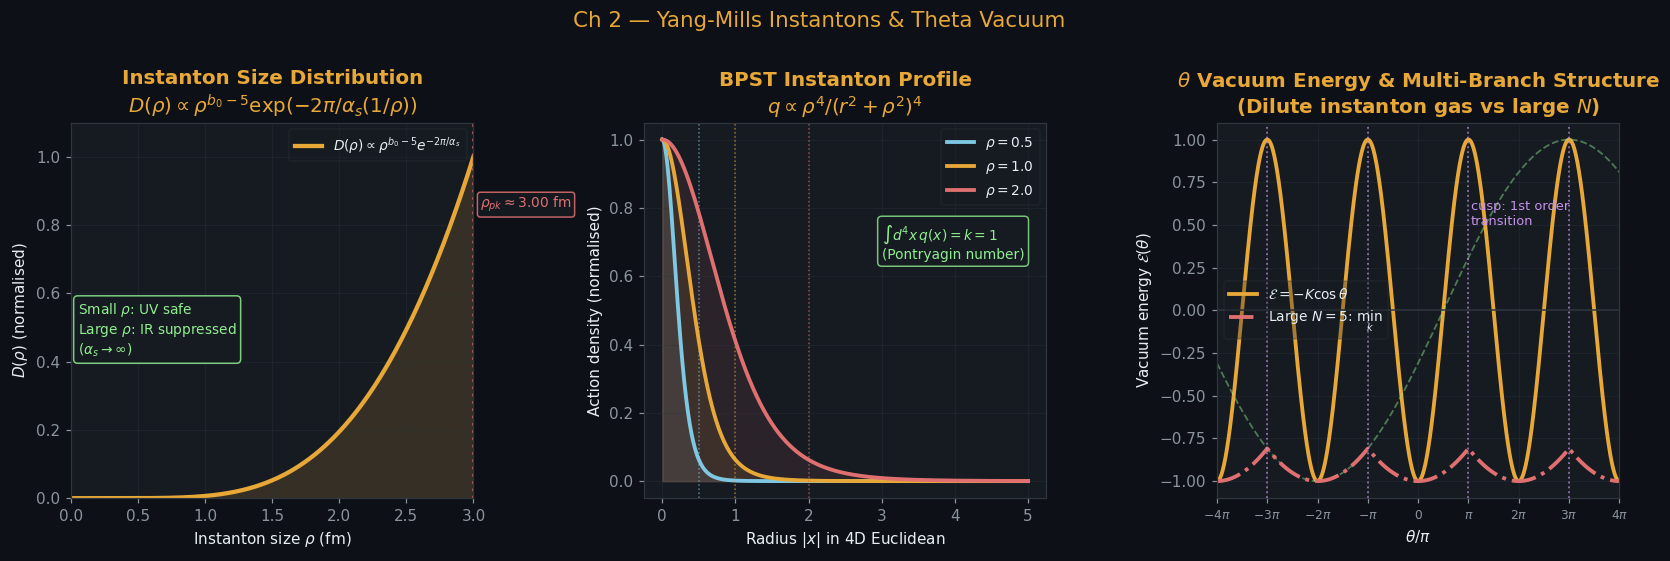

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Ch 2 — Yang-Mills Instantons & Theta Vacuum', color=AMBER, fontsize=14, y=1.01)

# ── Left: Instanton size distribution D(rho) ────────────────────────────
ax = axes[0]
rho = np.linspace(0.01, 3.0, 400)
b0 = 11 - 4  # b_0 for N_f=6, SU(3)
alpha_s_rho = 0.3 / (1 + 0.3*b0/(2*np.pi)*np.log(1/rho + 1))
D_rho = rho**(b0 - 5) * np.exp(-2*np.pi/alpha_s_rho)
D_rho /= D_rho.max()
ax.plot(rho, D_rho, color=AMBER, lw=2.8,
        label=r'$D(\rho)\propto\rho^{b_0-5}e^{-2\pi/\alpha_s}$')
ax.fill_between(rho, 0, D_rho, color=AMBER, alpha=0.15)
rho_pk = rho[np.argmax(D_rho)]
ax.axvline(rho_pk, color=RED, lw=1.8, ls=':', alpha=0.8)
ax.text(rho_pk+0.05, 0.85, fr'$\rho_{{pk}}\approx{rho_pk:.2f}$ fm',
        fontsize=9, color=RED,
        bbox=dict(boxstyle='round,pad=0.2', facecolor=SURF, edgecolor=RED, alpha=0.85))
ax.text(0.05, 0.42,
        'Small $\\rho$: UV safe\nLarge $\\rho$: IR suppressed\n($\\alpha_s\\to\\infty$)',
        fontsize=9, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.3', facecolor=SURF, edgecolor=GREEN, alpha=0.85))
ax.set_xlabel(r'Instanton size $\rho$ (fm)')
ax.set_ylabel(r'$D(\rho)$ (normalised)')
ax.set_title('Instanton Size Distribution\n'+
             r'$D(\rho)\propto\rho^{b_0-5}\exp(-2\pi/\alpha_s(1/\rho))$')
ax.legend(fontsize=9, labelcolor=TEXT)
ax.set_xlim(0, 3); ax.set_ylim(0, 1.1)
ax.grid(True, alpha=0.3)

# ── Middle:# ── Middle: Instanton density profile in 4D (radial) ─────────────────────
ax2 = axes[1]
r4 = np.linspace(0, 5, 400)
# BPST instanton profile: F^2 ~ 192 rho^4 / (r^2 + rho^2)^4
# Action density q(r) = 1/(8pi^2) * tr F^2
for rho_val, col, lbl in [(0.5, BLUE, r'$\rho=0.5$'), (1.0, AMBER, r'$\rho=1.0$'),
                            (2.0, RED, r'$\rho=2.0$')]:
    q_r = 192 * rho_val**4 / (r4**2 + rho_val**2)**4
    q_r_norm = q_r / q_r.max()
    ax2.plot(r4, q_r_norm, color=col, lw=2.5, label=lbl)
    ax2.fill_between(r4, 0, q_r_norm, color=col, alpha=0.1)
    ax2.axvline(rho_val, color=col, lw=1, ls=':', alpha=0.6)

# Integral annotation
ax2.text(3.0, 0.65, r'$\int d^4x\,q(x)=k=1$'+"\n"+r'(Pontryagin number)',
         fontsize=9, color=GREEN,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=SURF, edgecolor=GREEN, alpha=0.8))
ax2.set_xlabel(r'Radius $|x|$ in 4D Euclidean')
ax2.set_ylabel('Action density (normalised)')
ax2.set_title('BPST Instanton Profile\n'+r'$q\propto\rho^4/(r^2+\rho^2)^4$')
ax2.legend(fontsize=9, labelcolor=TEXT)
ax2.grid(True, alpha=0.3)

# ── Right: Theta vacuum energy — multi-branch (large N) ───────────────────
ax3 = axes[2]
theta_arr = np.linspace(-4*np.pi, 4*np.pi, 1200)

# Dilute instanton gas: E(theta) = -K * cos(theta)
K = 1.0
E_gas = -K * np.cos(theta_arr)
ax3.plot(theta_arr/np.pi, E_gas, color=AMBER, lw=2.5, label=r'$\mathcal{E}=-K\cos\theta$')

# Large N: multi-branch E_k(theta) = N^2 * (-cos((theta-2pi*k)/N))
N_large = 5
n_branches = 4
E_min = np.full_like(theta_arr, np.inf)
for k_b in range(-n_branches, n_branches+1):
    E_k = -(np.cos((theta_arr - 2*np.pi*k_b)/N_large))
    np.minimum(E_min, E_k, out=E_min)
    # Individual branches (faint)
    branch_c = [BLUE,GREEN,ORAN,PURP,RED]
ax3.plot(theta_arr/np.pi, E_k, color=branch_c[(k_b+2)%5], lw=1.2, ls='--', alpha=0.45)

ax3.plot(theta_arr/np.pi, E_min, color=RED, lw=2.5, ls='-.',
         label=f'Large $N={N_large}$: $\min_k$')

# Cusps at theta = (2k+1)*pi
for t_cusp in [-3, -1, 1, 3]:
    ax3.axvline(t_cusp, color=PURP, lw=1.2, ls=':', alpha=0.7)
ax3.text(1.05, 0.5, r'cusp: 1st order'+"\ntransition", fontsize=8.5, color=PURP)

ax3.axhline(0, color=EDGE, lw=1)
ax3.set_xlabel(r'$\theta/\pi$')
ax3.set_ylabel(r'Vacuum energy $\mathcal{E}(\theta)$')
ax3.set_title(r'$\theta$ Vacuum Energy & Multi-Branch Structure'+"\n(Dilute instanton gas vs large $N$)")
ax3.set_xlim(-4, 4)
ax3.set_xticks([-4,-3,-2,-1,0,1,2,3,4])
ax3.set_xticklabels([r'$-4\pi$',r'$-3\pi$',r'$-2\pi$',r'$-\pi$','0',
                      r'$\pi$',r'$2\pi$',r'$3\pi$',r'$4\pi$'], fontsize=8)
ax3.legend(fontsize=9, labelcolor=TEXT)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Visualization 3 · Chiral Anomaly: Chirality Production (Ch 3)

In parallel $\mathbf{E}\parallel\mathbf{B}$ fields, the lowest Landau level produces chirality at rate
$d(N_R-N_L)/dt = e^2\mathbf{E}\cdot\mathbf{B}/4\pi^2$.
Shown: **(a)** LLL spectrum and chirality flip, **(b)** anomaly coefficient $e^2/(16\pi^2)$ vs quark charge, **(c)** $\pi^0\to\gamma\gamma$ rate vs $N_c$.

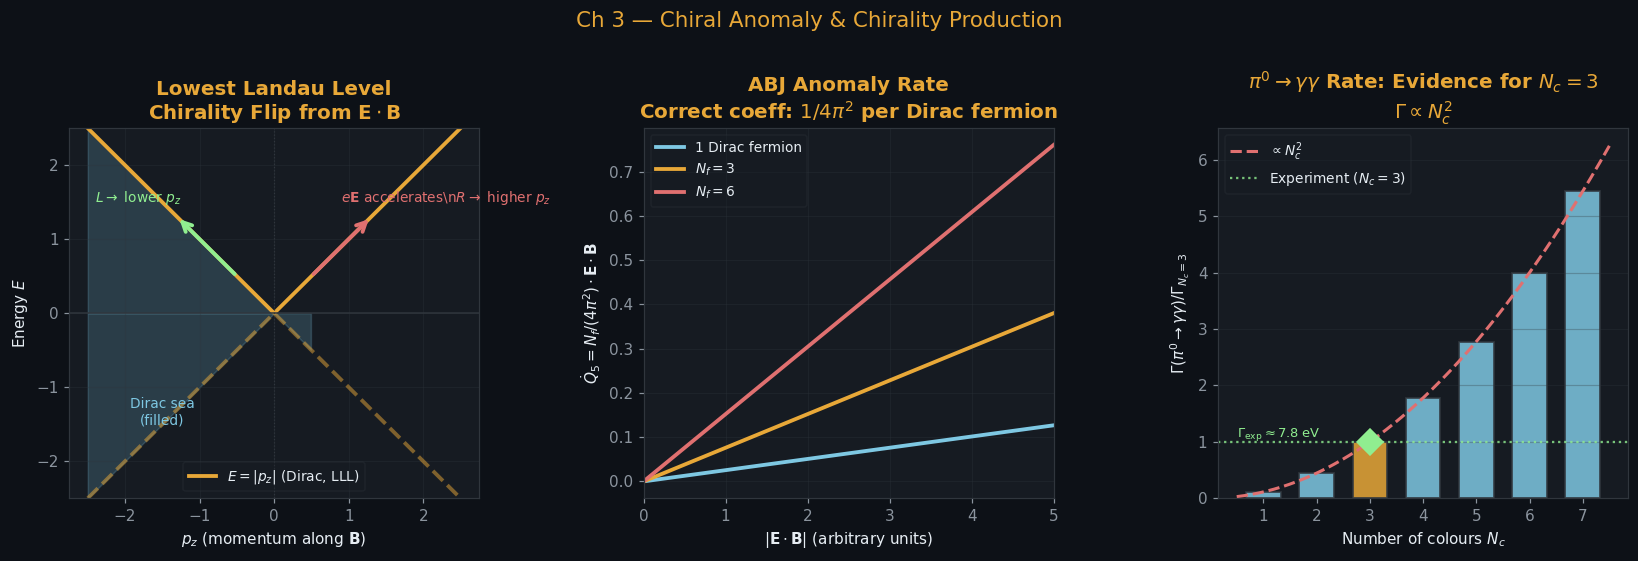

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Ch 3 — Chiral Anomaly & Chirality Production', color=AMBER, fontsize=14, y=1.01)

# ── Left: LLL dispersion & chirality flip ─────────────────────────────────
ax = axes[0]
pz = np.linspace(-2.5, 2.5, 300)
# Right-movers: E = |pz| (LLL dispersion)
ax.plot(pz, np.abs(pz), color=AMBER, lw=2.5, label=r'$E=|p_z|$ (Dirac, LLL)')
ax.plot(pz, -np.abs(pz), color=AMBER, lw=2.5, ls='--', alpha=0.5)

# Fermi sea filled up to pF
pF = 0.5
pz_fill = pz[(pz >= -2.5) & (pz <= pF)]
ax.fill_between(pz_fill, -np.abs(pz_fill), 0, color=BLUE, alpha=0.2)
ax.fill_between(pz_fill[pz_fill<0], np.abs(pz_fill[pz_fill<0]), 0, color=BLUE, alpha=0.2)

# Electric field acceleration arrow
ax.annotate('', xy=(pF+0.8, np.abs(pF+0.8)), xytext=(pF, np.abs(pF)),
            arrowprops=dict(arrowstyle='->', color=RED, lw=2.5, mutation_scale=15))
ax.text(pF+0.4, 1.5, r'$e\mathbf{E}$ accelerates\n$R\to$ higher $p_z$', fontsize=9, color=RED)

# Left movers
ax.annotate('', xy=(-pF-0.8, np.abs(-pF-0.8)), xytext=(-pF, np.abs(-pF)),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.5, mutation_scale=15))
ax.text(-2.4, 1.5, r'$L\to$ lower $p_z$', fontsize=9, color=GREEN)

ax.axhline(0, color=EDGE, lw=1)
ax.axvline(0, color=EDGE, lw=0.8, ls=':')
ax.set_xlabel(r'$p_z$ (momentum along $\mathbf{B}$)')
ax.set_ylabel('Energy $E$')
ax.set_title('Lowest Landau Level\nChirality Flip from $\mathbf{E}\\cdot\\mathbf{B}$')
ax.text(-1.5, -1.5, 'Dirac sea\n(filled)', ha='center', fontsize=9, color=BLUE)
ax.legend(fontsize=9, labelcolor=TEXT)
ax.set_ylim(-2.5, 2.5)
ax.grid(True, alpha=0.3)

# ── Middle: Anomaly rate vs E*B magnitude ─────────────────────────────────
ax2 = axes[1]
EB = np.linspace(0, 5, 300)  # in units of (100 MeV)^2

# Rate = e^2/(4pi^2) * E*B per unit volume (one Dirac fermion)
coeff = 1.0/(4*np.pi**2)  # correct ABJ: 1/(4pi^2) per Dirac fermion
for n_f, col, lbl in [(1, BLUE, '1 Dirac fermion'), (3, AMBER, r'$N_f=3$'), (6, RED, r'$N_f=6$')]:
    ax2.plot(EB, n_f*coeff*EB, color=col, lw=2.5, label=lbl)

ax2.set_xlabel(r'$|\mathbf{E}\cdot\mathbf{B}|$ (arbitrary units)')
ax2.set_ylabel(r'$\dot{Q}_5 = N_f/(4\pi^2)\cdot\mathbf{E}\cdot\mathbf{B}$')
ax2.set_title('ABJ Anomaly Rate\n'+r'Correct coeff: $1/4\pi^2$ per Dirac fermion')
ax2.legend(fontsize=9, labelcolor=TEXT)
ax2.set_xlim(0, 5)
ax2.grid(True, alpha=0.3)

# ── Right: pi0 -> gamma gamma rate vs N_c ─────────────────────────────────
ax3 = axes[2]
N_c_arr = np.arange(1, 8)
# Gamma ~ N_c^2 * alpha^2 * m_pi^3 / (192*pi^3*f_pi^2)
# Normalise to N_c=3
Gamma_rel = (N_c_arr / 3)**2
Gamma_exp = 1.0  # N_c=3 normalised

bar_cols = [AMBER if n == 3 else BLUE for n in N_c_arr]
bars = ax3.bar(N_c_arr, Gamma_rel, color=bar_cols, edgecolor=EDGE, lw=1.2, alpha=0.85, width=0.65)

# Theory curve N_c^2/9
N_c_cont = np.linspace(0.5, 7.5, 200)
ax3.plot(N_c_cont, (N_c_cont/3)**2, color=RED, lw=2, ls='--', label=r'$\propto N_c^2$')

# Experiment marker at N_c=3
ax3.axhline(1.0, color=GREEN, lw=1.5, ls=':', alpha=0.8, label='Experiment ($N_c=3$)')
ax3.plot(3, 1.0, 'D', color=GREEN, ms=12, zorder=5)
ax3.text(0.5, 1.08, r'$\Gamma_{\rm exp}\approx 7.8$ eV', fontsize=8.5, color=GREEN)

ax3.set_xlabel(r'Number of colours $N_c$')
ax3.set_ylabel(r'$\Gamma(\pi^0\to\gamma\gamma)/\Gamma_{N_c=3}$')
ax3.set_title(r'$\pi^0\to\gamma\gamma$ Rate: Evidence for $N_c=3$'+"\n"+r'$\Gamma\propto N_c^2$')
ax3.set_xticks(N_c_arr)
ax3.legend(fontsize=9, labelcolor=TEXT)
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

---
## Visualization 4 · Lattice Wilson Loop & Strong-Coupling Expansion (Ch 4)

At strong coupling ($\beta=2N/g^2\ll 1$), the Wilson loop obeys an area law
$\langle W\rangle\sim(\beta/2N)^{RT}$. Shown: **(a)** plaquette tiling of Wilson loop, **(b)** string tension vs $\beta$, **(c)** lattice vs continuum Dirac dispersion (doubler problem).

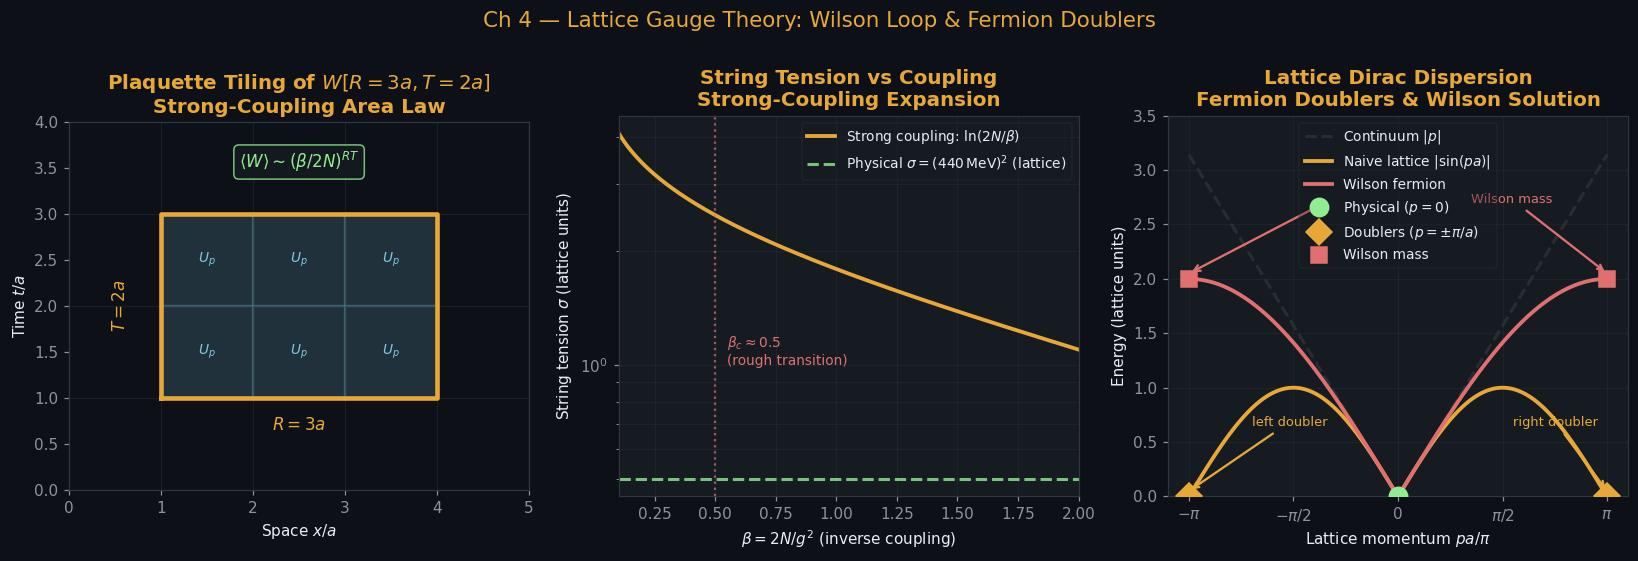

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Ch 4 — Lattice Gauge Theory: Wilson Loop & Fermion Doublers', color=AMBER, fontsize=14, y=1.01)

# ── Left: Plaquette tiling of a 3x2 Wilson loop ───────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
R_loop, T_loop = 3, 2
a_lat = 1.0  # lattice spacing

# Draw lattice
for xi in range(R_loop+3):
    ax.plot([xi, xi], [0, T_loop+2], color=EDGE, lw=0.8, alpha=0.4)
for yi in range(T_loop+3):
    ax.plot([0, R_loop+2], [yi, yi], color=EDGE, lw=0.8, alpha=0.4)

# Wilson loop boundary
loop_x = [1, 1+R_loop, 1+R_loop, 1, 1]
loop_y = [1, 1, 1+T_loop, 1+T_loop, 1]
ax.plot(loop_x, loop_y, color=AMBER, lw=3, zorder=5)
ax.text(1+R_loop/2, 0.65, f'$R={R_loop}a$', ha='center', color=AMBER, fontsize=11)
ax.text(0.55, 1+T_loop/2, f'$T={T_loop}a$', ha='center', va='center', color=AMBER, fontsize=11, rotation=90)

# Plaquette tiling (filled)
for xi in range(R_loop):
    for yi in range(T_loop):
        rect = plt.Rectangle((1+xi, 1+yi), 1, 1,
                               facecolor=BLUE, alpha=0.18, edgecolor=BLUE, lw=1.5)
        ax.add_patch(rect)
        ax.text(1.5+xi, 1.5+yi, r'$U_p$', ha='center', va='center',
                fontsize=9, color=BLUE)

ax.text(1+R_loop/2, 1+T_loop+0.5,
        r'$\langle W\rangle\sim(\beta/2N)^{RT}$',
        ha='center', fontsize=11, color=GREEN,
        bbox=dict(boxstyle='round,pad=0.3', facecolor=SURF, edgecolor=GREEN, alpha=0.8))

ax.set_xlim(0, R_loop+2); ax.set_ylim(0, T_loop+2)
ax.set_aspect('equal')
ax.set_title(f'Plaquette Tiling of $W[R={R_loop}a, T={T_loop}a]$\nStrong-Coupling Area Law')
ax.set_xlabel('Space $x/a$'); ax.set_ylabel('Time $t/a$')

# ── Middle: String tension sigma vs beta = 2N/g^2 ─────────────────────────
ax2 = axes[1]
beta_arr = np.linspace(0.1, 2.0, 300)
N_col = 3

# Strong coupling: sigma = -log(beta/2N)
sigma_sc = -np.log(beta_arr / (2*N_col))
sigma_sc = np.clip(sigma_sc, 0, None)

# Physical string tension (schematic continuum)
sigma_phys_line = np.ones_like(beta_arr) * 0.5  # flat (physical)
beta_cont = 6.0  # SU(3) continuum limit approx

ax2.semilogy(beta_arr, sigma_sc, color=AMBER, lw=2.5, label=r'Strong coupling: $\ln(2N/\beta)$')
ax2.axhline(0.5, color=GREEN, lw=2, ls='--', alpha=0.8, label=r'Physical $\sigma=(440\,\mathrm{MeV})^2$ (lattice)')

ax2.axvline(0.5, color=RED, lw=1.5, ls=':', alpha=0.7)
ax2.text(0.55, 1, r'$\beta_c\approx0.5$'+"\n"+'(rough transition)', fontsize=9, color=RED)

ax2.set_xlabel(r'$\beta = 2N/g^2$ (inverse coupling)')
ax2.set_ylabel(r'String tension $\sigma$ (lattice units)')
ax2.set_title('String Tension vs Coupling\nStrong-Coupling Expansion')
ax2.legend(fontsize=9, labelcolor=TEXT)
ax2.set_xlim(0.1, 2.0)
ax2.grid(True, which='both', alpha=0.3)

# ── Right: Lattice Dirac dispersion — doublers ─────────────────────────────
ax3 = axes[2]
pa = np.linspace(-np.pi, np.pi, 400)  # p*a in [-pi, pi]

# Naive lattice: sum_mu sin^2(p_mu a) in 1D
E_lattice = np.abs(np.sin(pa))
# Continuum: |p*a|
E_cont = np.abs(pa)
# Wilson: add r*(1-cos(pa))/a
r_wilson = 1.0
E_wilson = np.sqrt(np.sin(pa)**2 + (r_wilson*(1 - np.cos(pa)))**2)

ax3.plot(pa/np.pi, E_cont, color=EDGE, lw=2, ls='--', alpha=0.7, label='Continuum $|p|$')
ax3.plot(pa/np.pi, E_lattice, color=AMBER, lw=2.5, label='Naive lattice $|\\sin(pa)|$')
ax3.plot(pa/np.pi, E_wilson, color=RED, lw=2.5, label='Wilson fermion')

# Mark doublers
ax3.plot(0, 0, 'o', color=GREEN, ms=12, zorder=6, label='Physical ($p=0$)')
ax3.plot([-1, 1], [0, 0], 'D', color=AMBER, ms=12, zorder=6, label=r'Doublers ($p=\pm\pi/a$)')
ax3.plot([-1, 1], [r_wilson*2, r_wilson*2], 's', color=RED, ms=11, zorder=6, label='Wilson mass')

ax3.annotate('left doubler', xy=(-1,0.05), xytext=(-0.7,0.65), arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.5), fontsize=8.5, color=AMBER)
ax3.annotate('right doubler', xy=(1,0.05), xytext=(0.55,0.65), arrowprops=dict(arrowstyle='->', color=AMBER, lw=1.5), fontsize=8.5, color=AMBER)
ax3.annotate('Wilson mass', xy=(1,2.05), xytext=(0.35,2.7), arrowprops=dict(arrowstyle='->', color=RED, lw=1.5), fontsize=8.5, color=RED)
ax3.annotate('', xy=(-1,2.05), xytext=(-0.35,2.7), arrowprops=dict(arrowstyle='->', color=RED, lw=1.5))

ax3.set_xlabel(r'Lattice momentum $pa/\pi$')
ax3.set_ylabel('Energy (lattice units)')
ax3.set_title('Lattice Dirac Dispersion\nFermion Doublers & Wilson Solution')
ax3.legend(fontsize=9, labelcolor=TEXT)
ax3.set_xticks([-1, -0.5, 0, 0.5, 1])
ax3.set_xticklabels([r'$-\pi$', r'$-\pi/2$', '0', r'$\pi/2$', r'$\pi$'])
ax3.set_ylim(0, 3.5)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Visualization 5 · Chiral Condensate & GOR Relation (Ch 5)

The GOR relation $m_\pi^2 f_\pi^2 = -(m_u+m_d)\langle\bar\psi\psi\rangle$ connects pion mass to quark mass.
Shown: **(a)** effective potential showing SSB, **(b)** $m_\pi^2$ vs $m_q$ (GOR), **(c)** Skyrmion profile.

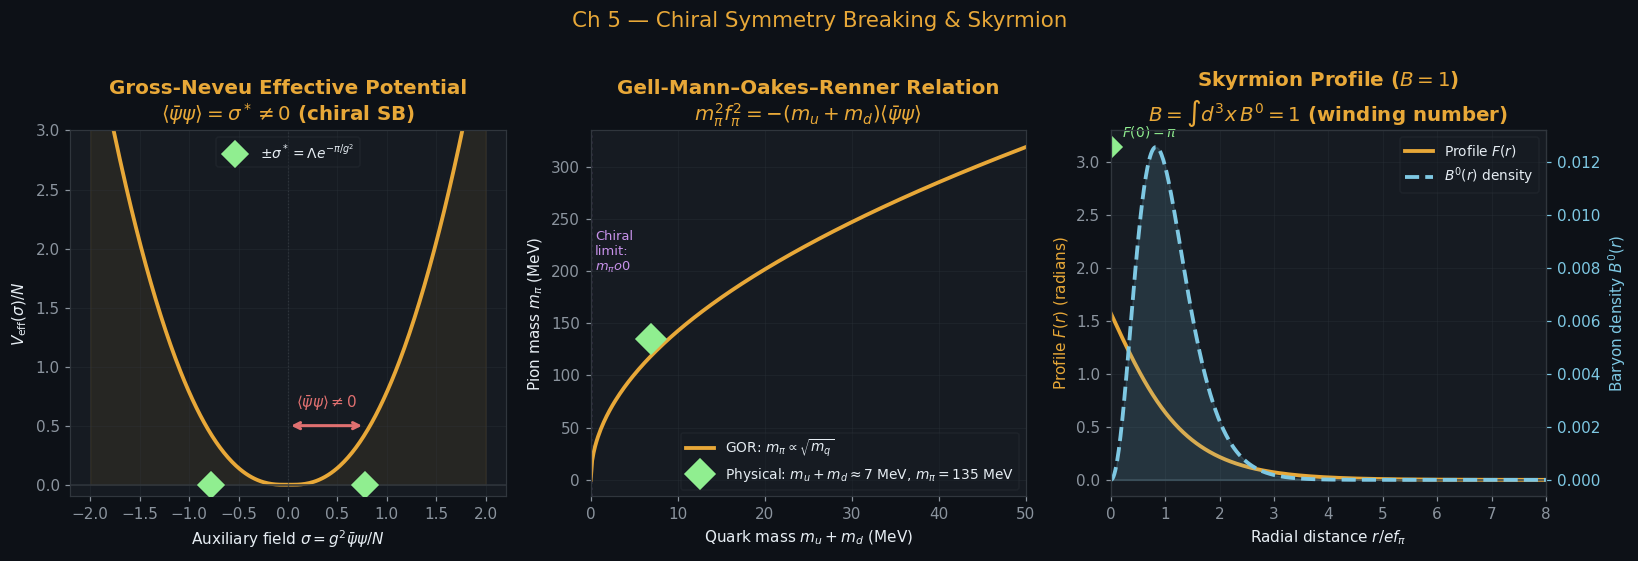

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Ch 5 — Chiral Symmetry Breaking & Skyrmion', color=AMBER, fontsize=14, y=1.01)

# ── Left: Effective potential V(sigma) — Mexican hat ──────────────────────
ax = axes[0]
sigma_arr = np.linspace(-2, 2, 400)

# V_eff(sigma) = N/(2g^2)*sigma^2 - N/pi*[sigma^2*ln(Lambda/|sigma|) - sigma^2/2]
# Simplified: V = a*sigma^2 - b*sigma^2 * ln(sigma^2 + eps)
Lambda = 1.0
g_sq = 0.8
eps = 1e-6
V = sigma_arr**2 / (2*g_sq) - (sigma_arr**2 * np.log(Lambda / (np.abs(sigma_arr) + eps)) - sigma_arr**2/2) / np.pi
V_norm = V - V.min()

ax.plot(sigma_arr, V_norm, color=AMBER, lw=2.5)
ax.fill_between(sigma_arr, 0, V_norm, color=AMBER, alpha=0.08)

# Minima
sigma_star = 0.78  # approximate for these parameters
ax.plot([-sigma_star, sigma_star], [0, 0], 'D', color=GREEN, ms=12, zorder=5,
        label=r'$\pm\sigma^*=\Lambda e^{-\pi/g^2}$')
ax.axhline(0, color=EDGE, lw=1)
ax.axvline(0, color=EDGE, lw=0.8, ls=':')

ax.annotate('', xy=(sigma_star, 0.5), xytext=(0, 0.5),
            arrowprops=dict(arrowstyle='<->', color=RED, lw=2))
ax.text(sigma_star/2, 0.65, r'$\langle\bar\psi\psi\rangle\neq 0$', ha='center', fontsize=10, color=RED)

ax.set_xlabel(r'Auxiliary field $\sigma = g^2\bar\psi\psi/N$')
ax.set_ylabel(r'$V_{\rm eff}(\sigma)/N$')
ax.set_title('Gross-Neveu Effective Potential\n'+r'$\langle\bar\psi\psi\rangle=\sigma^*\neq 0$ (chiral SB)')
ax.legend(fontsize=9, labelcolor=TEXT)
ax.set_ylim(-0.1, 3)
ax.grid(True, alpha=0.3)

# ── Middle: GOR relation: m_pi^2 vs m_q ──────────────────────────────────
ax2 = axes[1]
m_q = np.linspace(0, 50, 300)  # MeV
f_pi = 93.0  # MeV
# |<psi psi>|^(1/3) ~ 260 MeV -> |<psi psi>| ~ 1.76e7 MeV^3
condensate = (260)**3  # MeV^3
m_pi2_GOR = condensate * m_q / f_pi**2  # MeV^2
m_pi_GOR = np.sqrt(m_pi2_GOR)

ax2.plot(m_q, m_pi_GOR, color=AMBER, lw=2.5, label=r'GOR: $m_\pi\propto\sqrt{m_q}$')

# Physical point
# Physical: m_u~2.2, m_d~4.7 MeV -> sum~6.9 MeV; m_pi=134.98 MeV
ax2.plot(6.9, 134.98, 'D', color=GREEN, ms=14, zorder=5,
         label=r'Physical: $m_u+m_d\approx7$ MeV, $m_\pi=135$ MeV')

# Chiral limit
ax2.axvline(0, color=PURP, lw=1.5, ls=':', alpha=0.8)
ax2.text(0.5, 200, 'Chiral\nlimit:\n$m_\pi\to 0$', fontsize=8.5, color=PURP)

ax2.set_xlabel(r'Quark mass $m_u+m_d$ (MeV)')
ax2.set_ylabel(r'Pion mass $m_\pi$ (MeV)')
ax2.set_title('Gell-Mann–Oakes–Renner Relation\n'+r'$m_\pi^2 f_\pi^2 = -(m_u+m_d)\langle\bar\psi\psi\rangle$')
ax2.legend(fontsize=9, labelcolor=TEXT)
ax2.set_xlim(0, 50)
ax2.grid(True, alpha=0.3)

# ── Right: Skyrmion profile F(r) ──────────────────────────────────────────
ax3 = axes[2]
r_sk = np.linspace(0, 8, 500)
# Skyrmion profile F(r): F(0)=pi, F(inf)=0, approximately:
F_sk = np.pi * np.exp(-r_sk * 0.8)  # schematic exponential (exact requires ODE)
# More realistic: F(r) ~ pi/(1 + (r/r0)^2) [approximate rational form]
r0 = 0.9
F_sk2 = 2 * np.arctan(np.exp(-r_sk / r0))  # kink-like

# Baryon number density B^0(r) = -1/(2pi^2) * sin^2(F)*F' (for hedgehog)
dF_dr = np.gradient(F_sk2, r_sk)
B_density = -(r_sk**2) * np.sin(F_sk2)**2 * dF_dr / (2 * np.pi**2)
B_density = np.maximum(B_density, 0)

ax3_twin = ax3.twinx()
ax3.plot(r_sk, F_sk2, color=AMBER, lw=2.5, label='Profile $F(r)$')
ax3_twin.plot(r_sk, B_density, color=BLUE, lw=2.5, ls='--', label=r'$B^0(r)$ density')
ax3_twin.fill_between(r_sk, 0, B_density, color=BLUE, alpha=0.15)

# Boundary conditions
ax3.plot(0, np.pi, 'D', color=GREEN, ms=10, zorder=5)
ax3.text(0.2, np.pi+0.1, r'$F(0)=\pi$', fontsize=9, color=GREEN)
ax3.axhline(0, color=EDGE, lw=1)

ax3.set_xlabel(r'Radial distance $r/e f_\pi$')
ax3.set_ylabel(r'Profile $F(r)$ (radians)', color=AMBER)
ax3_twin.set_ylabel(r'Baryon density $B^0(r)$', color=BLUE)
ax3.set_title('Skyrmion Profile ($B=1$)\n'+r'$B=\int d^3x\,B^0=1$ (winding number)')

lines1, labels1 = ax3.get_legend_handles_labels()
lines2, labels2 = ax3_twin.get_legend_handles_labels()
ax3.legend(lines1+lines2, labels1+labels2, fontsize=9, labelcolor=TEXT)
ax3.set_xlim(0, 8)
ax3.grid(True, alpha=0.3)
ax3_twin.tick_params(axis='y', colors=BLUE)

plt.tight_layout()
plt.show()

---
## Visualization 6 · Large N: Scaling & Witten-Veneziano (Ch 6)

At large $N$: widths scale as $1/N^k$, $f_\pi^2\sim N$, and the Witten-Veneziano formula
$m_{\eta'}^2=2N_f\chi_{\rm YM}/f_\pi^2$ predicts $m_{\eta'}\approx958$ MeV.
Shown: **(a)** $N$-scaling of widths, **(b)** Witten-Veneziano prediction vs lattice $\chi_{\rm YM}$, **(c)** genus expansion.

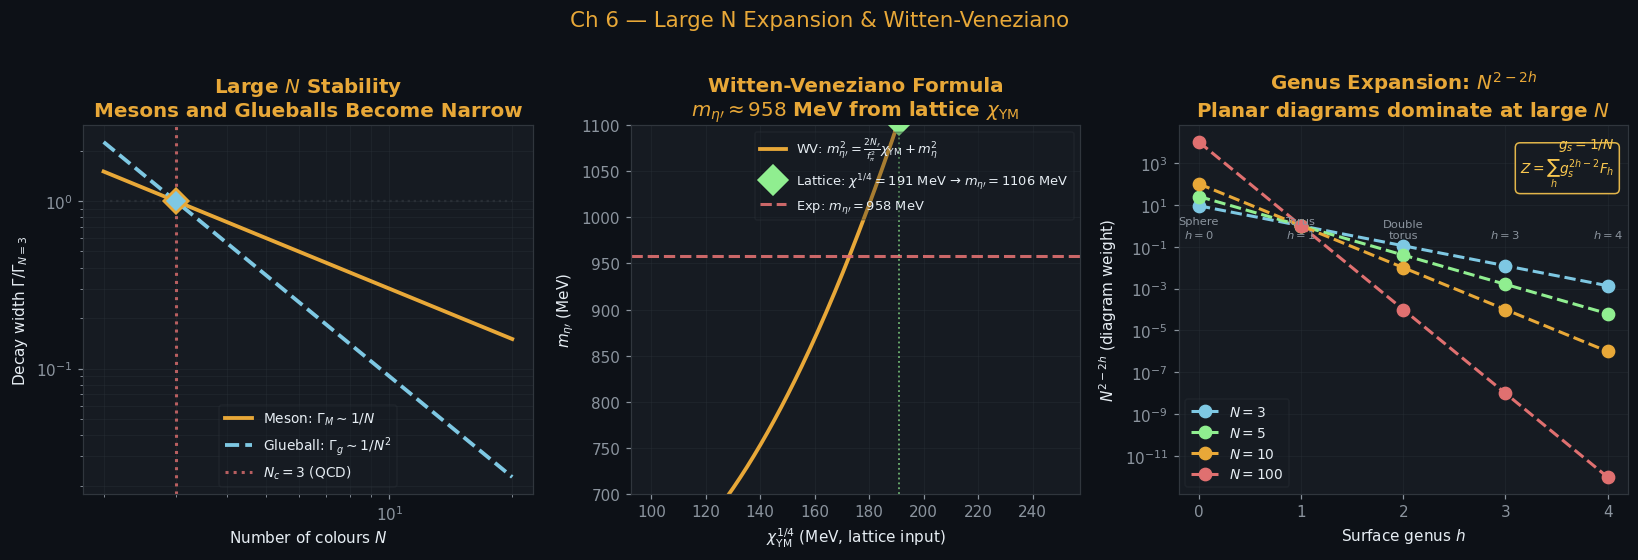

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Ch 6 — Large N Expansion & Witten-Veneziano', color=AMBER, fontsize=14, y=1.01)

# ── Left: N-scaling of decay widths ──────────────────────────────────────
ax = axes[0]
N_cont = np.linspace(2, 20, 300)

# Normalise to N=3
Gamma_meson  = (3/N_cont)**1
Gamma_glue   = (3/N_cont)**2

ax.loglog(N_cont, Gamma_meson, color=AMBER, lw=2.5, label=r'Meson: $\Gamma_M\sim 1/N$')
ax.loglog(N_cont, Gamma_glue, color=BLUE, lw=2.5, ls='--', label=r'Glueball: $\Gamma_g\sim 1/N^2$')
ax.loglog(N_cont, np.ones_like(N_cont), color=EDGE, lw=1.5, ls=':', alpha=0.7)

ax.axvline(3, color=RED, lw=2, ls=':', alpha=0.8, label='$N_c=3$ (QCD)')
ax.plot(3, 1.0, 'D', color=AMBER, ms=12, zorder=5)
ax.plot(3, 1.0, 'D', color=BLUE, ms=8, zorder=5)

ax.annotate(r'$N\to\infty$: stable', xy=(15, 0.01), xytext=(12, 0.2),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.5),
            fontsize=9, color=GREEN)

ax.set_xlabel(r'Number of colours $N$')
ax.set_ylabel(r'Decay width $\Gamma/\Gamma_{N=3}$')
ax.set_title('Large $N$ Stability\nMesons and Glueballs Become Narrow')
ax.legend(fontsize=9, labelcolor=TEXT)
ax.grid(True, which='both', alpha=0.3)

# ── Middle: Witten-Veneziano: m_eta' prediction ───────────────────────────
ax2 = axes[1]
Nf = 3
f_pi_MeV = 93.0
m_eta_MeV = 548.0

# x = chi_YM^(1/4) varying
chi14_arr = np.linspace(100, 250, 300)  # MeV
chi_arr = chi14_arr**4  # MeV^4
m_etap2 = 2*Nf * chi_arr / f_pi_MeV**2 + m_eta_MeV**2
m_etap = np.sqrt(m_etap2)

ax2.plot(chi14_arr, m_etap, color=AMBER, lw=2.5,
         label=r'WV: $m_{\eta\prime}^2=\frac{2N_f}{f_\pi^2}\chi_{\rm YM}+m_\eta^2$')

# Physical point
chi14_phys = 191.0
chi_phys = chi14_phys**4
m_etap_phys = np.sqrt(2*Nf*chi_phys/f_pi_MeV**2 + m_eta_MeV**2)

ax2.plot(chi14_phys, m_etap_phys, 'D', color=GREEN, ms=14, zorder=5,
         label=f'Lattice: $\chi^{{1/4}}=191$ MeV → $m_{{\eta\prime}}={m_etap_phys:.0f}$ MeV')
ax2.axhline(958, color=RED, lw=2, ls='--', alpha=0.9, label=r'Exp: $m_{\eta\prime}=958$ MeV')
ax2.axvline(chi14_phys, color=GREEN, lw=1.2, ls=':', alpha=0.7)

ax2.set_xlabel(r'$\chi_{\rm YM}^{1/4}$ (MeV, lattice input)')
ax2.set_ylabel(r'$m_{\eta\prime}$ (MeV)')
ax2.set_title('Witten-Veneziano Formula\n'+r'$m_{\eta\prime}\approx958$ MeV from lattice $\chi_{\rm YM}$')
ax2.legend(fontsize=8.5, labelcolor=TEXT)
ax2.set_ylim(700, 1100)
ax2.grid(True, alpha=0.3)

# ── Right: Genus expansion N^(2-2h) ──────────────────────────────────────
ax3 = axes[2]
h_vals = np.arange(0, 5)
N_plot_vals = [3, 5, 10, 100]
colors_N = [BLUE, GREEN, AMBER, RED]

for N_v, col in zip(N_plot_vals, colors_N):
    weights = N_v**(2 - 2*h_vals.astype(float))
    ax3.semilogy(h_vals, weights, 'o--', color=col, lw=2, ms=8,
                 label=f'$N={N_v}$')

genus_names = ['Sphere\n$h=0$', 'Torus\n$h=1$', 'Double\ntorus', '$h=3$', '$h=4$']
for h, lbl in zip(h_vals, genus_names):
    ax3.text(h, 0.25, lbl, ha='center', fontsize=7.5, color=DIM)

ax3.text(0.97, 0.97, r'$g_s=1/N$'+chr(10)+r'$Z=\sum_h g_s^{2h-2}F_h$', ha='right', va='top', fontsize=9, color=YELL, transform=ax3.transAxes, bbox=dict(boxstyle='round,pad=0.35', facecolor=SURF, edgecolor=YELL, alpha=0.90))

ax3.set_xlabel(r'Surface genus $h$')
ax3.set_ylabel(r'$N^{2-2h}$ (diagram weight)')
ax3.set_title(r'Genus Expansion: $N^{2-2h}$'+"\nPlanar diagrams dominate at large $N$")
ax3.set_xticks(h_vals)
ax3.legend(fontsize=9, labelcolor=TEXT)
ax3.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

---
## Visualization 7 · Bosonisation: Sine-Gordon & Schwinger Model (Ch 7)

The exact 2D duality: free Dirac fermion $\leftrightarrow$ compact boson.
Massive Thirring $\leftrightarrow$ Sine-Gordon with $\beta^2/4\pi=1/(1+g/\pi)$.
The Schwinger model acquires photon mass $m_\gamma=e/\sqrt{\pi}$.
Shown: **(a)** SG kink profiles, **(b)** MT–SG duality map, **(c)** 2D QED potential.

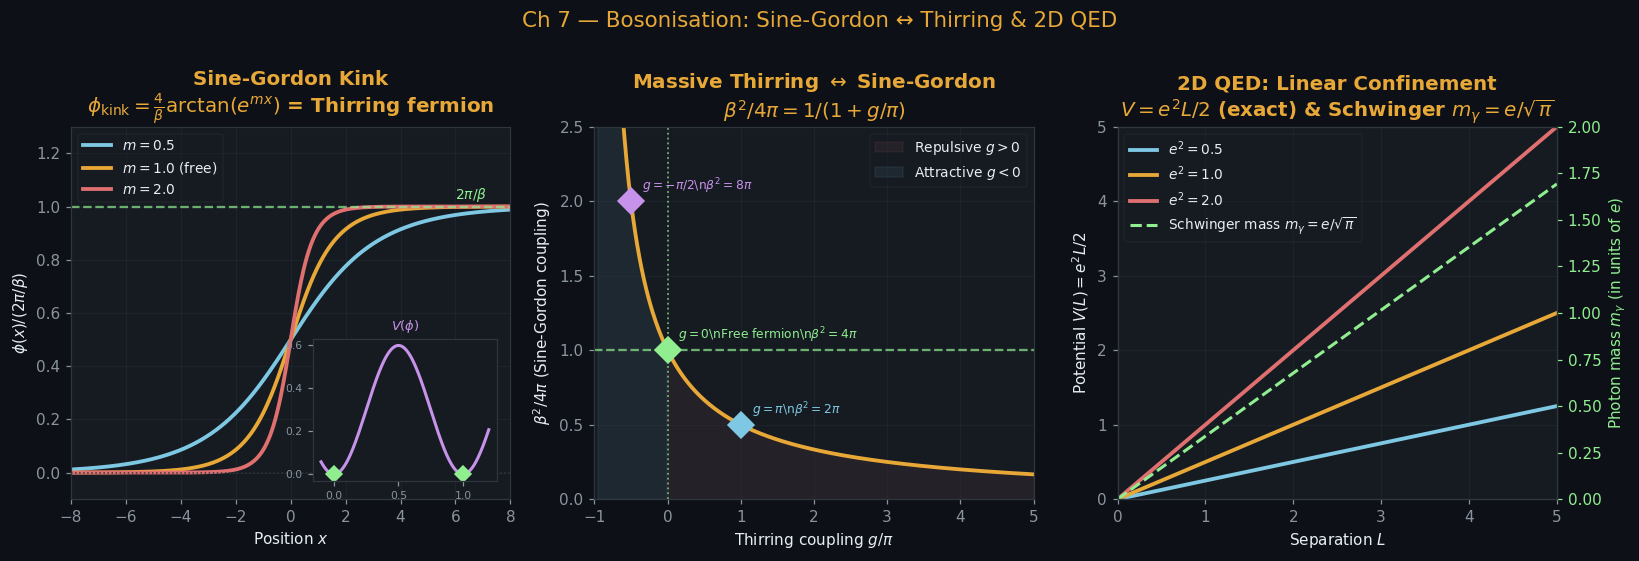

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Ch 7 — Bosonisation: Sine-Gordon ↔ Thirring & 2D QED', color=AMBER, fontsize=14, y=1.01)

# ── Left: Sine-Gordon kink profiles ──────────────────────────────────────
ax = axes[0]
x = np.linspace(-8, 8, 500)
beta_free = np.sqrt(4*np.pi)  # free fermion point
phi_max = 2*np.pi/beta_free   # top vacuum

for m_val, col, lbl in [(0.5, BLUE, r'$m=0.5$'), (1.0, AMBER, r'$m=1.0$ (free)'),
                          (2.0, RED, r'$m=2.0$')]:
    phi_kink = (4/beta_free) * np.arctan(np.exp(m_val * x))
    ax.plot(x, phi_kink/phi_max, color=col, lw=2.5, label=lbl)

ax.axhline(0, color=EDGE, lw=1, ls=':')
ax.axhline(1, color=GREEN, lw=1.5, ls='--', alpha=0.7)
ax.text(6, 1.03, r'$2\pi/\beta$', fontsize=9, color=GREEN)

# SG potential inset
phi_pot = np.linspace(-0.1, 1.2, 200)
V_pot = 0.3*(1 - np.cos(2*np.pi*phi_pot))
ax_in = ax.inset_axes([0.55, 0.05, 0.42, 0.38])
ax_in.set_facecolor(SURF)
ax_in.plot(phi_pot, V_pot, color=PURP, lw=2)
ax_in.plot([0, 1], [0, 0], 'D', color=GREEN, ms=7)
ax_in.set_title(r'$V(\phi)$', fontsize=8.5, color=PURP)
ax_in.tick_params(labelsize=7, colors=DIM)
for sp in ax_in.spines.values(): sp.set_edgecolor(EDGE)

ax.set_xlabel('Position $x$')
ax.set_ylabel(r'$\phi(x)/(2\pi/\beta)$')
ax.set_title('Sine-Gordon Kink\n'+r'$\phi_{\rm kink}=\frac{4}{\beta}\arctan(e^{mx})$ = Thirring fermion')
ax.legend(fontsize=9, labelcolor=TEXT)
ax.set_xlim(-8, 8); ax.set_ylim(-0.1, 1.3)
ax.grid(True, alpha=0.3)

# ── Middle: MT-SG duality map ─────────────────────────────────────────────
ax2 = axes[1]
g_thirring = np.linspace(-np.pi*0.95, 5*np.pi, 400)
beta2_4pi = 1/(1 + g_thirring/np.pi)
mask = beta2_4pi > 0

ax2.plot(g_thirring[mask]/np.pi, beta2_4pi[mask], color=AMBER, lw=2.5)

# Phase regions
g_m = g_thirring[mask]
b_m = beta2_4pi[mask]
ax2.fill_between(g_m/np.pi, 0, b_m, where=(g_m>0), color=RED, alpha=0.08,
                  label='Repulsive $g>0$')
ax2.fill_between(g_m/np.pi, 0, b_m, where=(g_m<0), color=BLUE, alpha=0.08,
                  label='Attractive $g<0$')

# Special points
for g_sp, lbl, col in [(0, r'$g=0$\nFree fermion\n$\beta^2=4\pi$', GREEN),
                         (1, r'$g=\pi$\n$\beta^2=2\pi$', BLUE),
                         (-0.5, r'$g=-\pi/2$\n$\beta^2=8\pi$', PURP)]:
    b_sp = 1/(1+g_sp)
    ax2.plot(g_sp, b_sp, 'D', color=col, ms=12, zorder=5)
    ax2.text(g_sp+0.15, b_sp+0.07, lbl, fontsize=8, color=col)

ax2.axhline(1, color=GREEN, lw=1.5, ls='--', alpha=0.7)
ax2.axvline(0, color=GREEN, lw=1.2, ls=':', alpha=0.7)
ax2.set_xlabel(r'Thirring coupling $g/\pi$')
ax2.set_ylabel(r'$\beta^2/4\pi$ (Sine-Gordon coupling)')
ax2.set_title('Massive Thirring $\\leftrightarrow$ Sine-Gordon\n'+
              r'$\beta^2/4\pi=1/(1+g/\pi)$')
ax2.legend(fontsize=9, labelcolor=TEXT)
ax2.set_xlim(-1, 5); ax2.set_ylim(0, 2.5)
ax2.grid(True, alpha=0.3)

# ── Right: 2D QED (Schwinger): V(L) and photon mass ──────────────────────
ax3 = axes[2]
L_arr = np.linspace(0, 5, 300)

for e2_val, col, lbl in [(0.5, BLUE, r'$e^2=0.5$'), (1.0, AMBER, r'$e^2=1.0$'),
                           (2.0, RED, r'$e^2=2.0$')]:
    V_L = e2_val/2 * L_arr
    ax3.plot(L_arr, V_L, color=col, lw=2.5, label=lbl)

# Schwinger mass annotation
e_arr = np.linspace(0, 3, 200)
m_gamma = e_arr / np.sqrt(np.pi)
ax3_twin = ax3.twinx()
ax3_twin.plot(e_arr*5/3, m_gamma, color=GREEN, lw=2, ls='--',
              label=r'Schwinger mass $m_\gamma=e/\sqrt{\pi}$')
ax3_twin.set_ylabel(r'Photon mass $m_\gamma$ (in units of $e$)', color=GREEN)
ax3_twin.tick_params(axis='y', colors=GREEN)
ax3_twin.set_ylim(0, 2)

ax3.set_xlabel(r'Separation $L$')
ax3.set_ylabel(r'Potential $V(L) = e^2 L/2$')
ax3.set_title('2D QED: Linear Confinement\n'+r'$V=e^2L/2$ (exact) & Schwinger $m_\gamma=e/\sqrt{\pi}$')

lines1, labels1 = ax3.get_legend_handles_labels()
lines2, labels2 = ax3_twin.get_legend_handles_labels()
ax3.legend(lines1+lines2, labels1+labels2, fontsize=9, labelcolor=TEXT)
ax3.set_xlim(0, 5); ax3.set_ylim(0, 5)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Visualization 8 · Chern-Simons Theory & 3D Dualities (Ch 8)

The $U(1)_k$ CS theory: Hall conductance $\sigma_{xy}=k/2\pi$, GSD on $T^2=|k|$, anyon statistics $\theta=\pi/k$.
Flux attachment: boson + CS = fermion (core 3D duality).
Shown: **(a)** Hall conductance ladder, **(b)** anyon braiding statistics, **(c)** Polyakov confinement string tension.

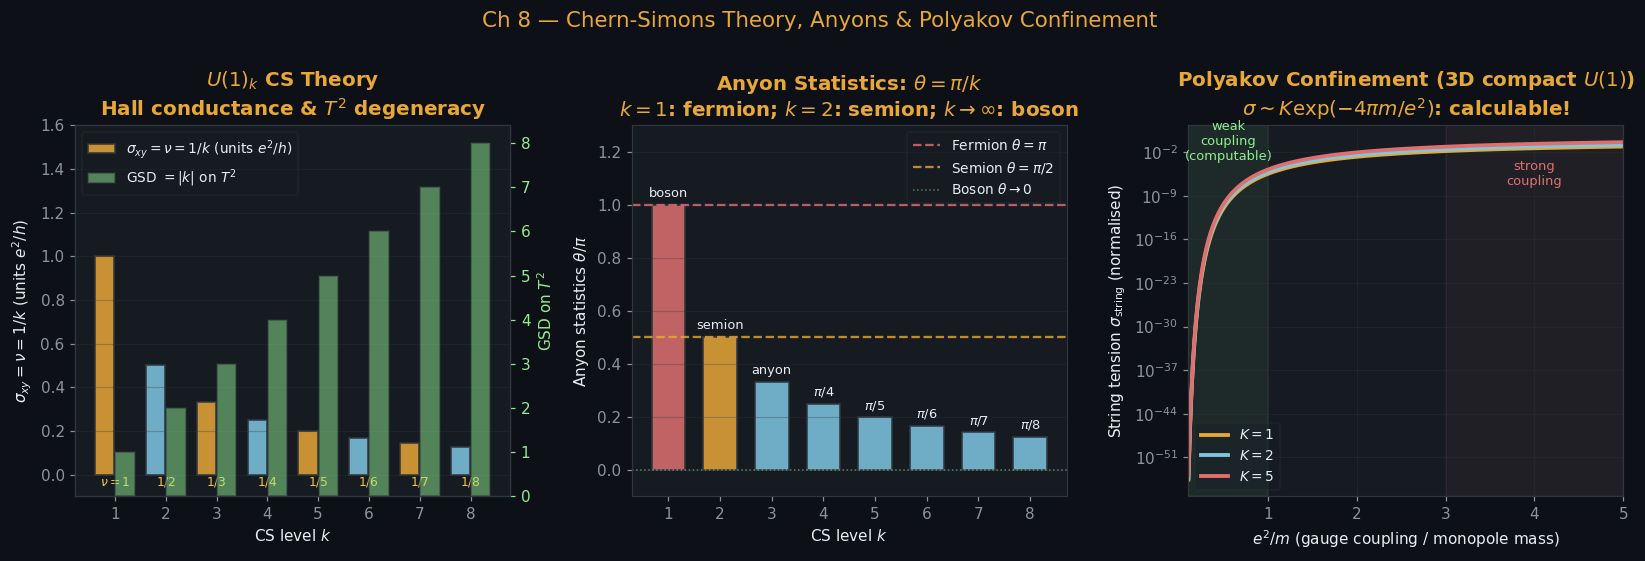

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Ch 8 — Chern-Simons Theory, Anyons & Polyakov Confinement', color=AMBER, fontsize=14, y=1.01)

# ── Left: Hall conductance & GSD vs CS level k ───────────────────────────
ax = axes[0]
k_arr = np.arange(1, 9)
sigma_xy = 1.0 / k_arr   # FQHE: nu=1/k = sigma_xy (in units e^2/h)
GSD = k_arr  # ground state degeneracy on T^2

bar_cols = [AMBER if k%2==1 else BLUE for k in k_arr]
bars1 = ax.bar(k_arr - 0.2, sigma_xy, width=0.38, color=bar_cols, alpha=0.85,
               edgecolor=EDGE, lw=1.2, label=r'$\sigma_{xy}=\nu=1/k$ (units $e^2/h$)')

ax2_twin = ax.twinx()
ax2_twin.bar(k_arr + 0.2, GSD, width=0.38, color=GREEN, alpha=0.5,
             edgecolor=EDGE, lw=1.2, label=r'GSD $=|k|$ on $T^2$')
ax2_twin.set_ylabel(r'GSD on $T^2$', color=GREEN)
ax2_twin.tick_params(axis='y', colors=GREEN)

# FQH filling labels
fqh = [r'$\nu=1$', r'$1/2$', r'$1/3$', r'$1/4$', r'$1/5$', r'$1/6$', r'$1/7$', r'$1/8$']
for k, f in zip(k_arr, fqh):
    ax.text(k, -0.05, f, ha='center', fontsize=8, color=YELL)

ax.set_xlabel(r'CS level $k$')
ax.set_ylabel(r'$\sigma_{xy}=\nu=1/k$ (units $e^2/h$)')
ax.set_title(r'$U(1)_k$ CS Theory'+"\n"+r'Hall conductance & $T^2$ degeneracy')
ax.set_xticks(k_arr)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax.legend(lines1+lines2, labels1+labels2, fontsize=9, labelcolor=TEXT, loc='upper left')
ax.set_ylim(-0.1, 1.6)
ax.grid(True, axis='y', alpha=0.3)

# ── Middle: Anyon braiding statistics theta = pi/k ────────────────────────
ax2 = axes[1]
k_anyon = np.arange(1, 9)
# theta=pi/k: k=1 -> fermion (theta=pi), k=2 -> semion (theta=pi/2), large k -> boson
theta_norm = 1.0 / k_anyon  # theta/pi = 1/k
anyon_cols = [RED if k==1 else (AMBER if k==2 else BLUE) for k in k_anyon]
ax2.bar(k_anyon, theta_norm, color=anyon_cols, alpha=0.85, edgecolor=EDGE, lw=1.2, width=0.65)

ax2.axhline(1.0, color=RED,   lw=1.5, ls='--', alpha=0.8, label=r'Fermion $\theta=\pi$')
ax2.axhline(0.5, color=AMBER, lw=1.5, ls='--', alpha=0.8, label=r'Semion $\theta=\pi/2$')
ax2.axhline(0.0, color=GREEN, lw=1.0, ls=':',  alpha=0.5, label=r'Boson $\theta\to 0$')

stats_labels = ['boson', 'semion', 'anyon', '', '', '', '', '']
for k, t, lbl in zip(k_anyon, theta_norm, stats_labels):
    ax2.text(k, t+0.03, lbl if lbl else f'$\pi/{k}$',
             ha='center', fontsize=8.5, color=TEXT)

ax2.set_xlabel(r'CS level $k$')
ax2.set_ylabel(r'Anyon statistics $\theta/\pi$')
ax2.set_title(r'Anyon Statistics: $\theta=\pi/k$'+chr(10)+r'$k=1$: fermion; $k=2$: semion; $k\to\infty$: boson')
ax2.set_xticks(k_anyon)
ax2.set_ylim(-0.1, 1.3)
ax2.legend(fontsize=9, labelcolor=TEXT)
ax2.grid(True, axis='y', alpha=0.3)

# ── Right: Polyakov confinement — string tension vs coupling ──────────────
ax3 = axes[2]
e2_over_m = np.linspace(0.1, 5, 300)  # e^2/m (dimensionless)

# Polyakov: sigma ~ K * exp(-4*pi*m/e^2) = K * exp(-4*pi / (e^2/m))
K_poly = 1.0
sigma_poly = K_poly * np.exp(-4*np.pi / e2_over_m)

# Different UV cutoffs / prefactors
for K_val, col, lbl in [(1.0, AMBER, r'$K=1$'), (2.0, BLUE, r'$K=2$'), (5.0, RED, r'$K=5$')]:
    ax3.semilogy(e2_over_m, K_val * np.exp(-4*np.pi/e2_over_m),
                 color=col, lw=2.5, label=lbl)

# Weak coupling regime
ax3.axvspan(0.1, 1.0, color=GREEN, alpha=0.07)
ax3.text(0.55, 5e-4, 'weak\ncoupling\n(computable)', ha='center', fontsize=8.5, color=GREEN)

# Large coupling (non-perturbative)
ax3.axvspan(3.0, 5.0, color=RED, alpha=0.06)
ax3.text(4.0, 5e-8, 'strong\ncoupling', ha='center', fontsize=8.5, color=RED)

ax3.set_xlabel(r'$e^2/m$ (gauge coupling / monopole mass)')
ax3.set_ylabel(r'String tension $\sigma_{\rm string}$ (normalised)')
ax3.set_title(r'Polyakov Confinement (3D compact $U(1)$)'+"\n"+
              r'$\sigma\sim K\exp(-4\pi m/e^2)$: calculable!')
ax3.legend(fontsize=9, labelcolor=TEXT)
ax3.set_xlim(0.1, 5)
ax3.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

---
## Summary

| # | Topic | Key Result Visualised |
|---|---|---|
| 1 | Dirac Monopole | $eg=2\pi n$; Witten effect dyon spectrum |
| 2 | YM Instantons | BPS bound $S\geq 8\pi^2|k|/g^2$; $\theta$ vacuum |
| 3 | Chiral Anomaly | LLL chirality flip; $\pi^0\to\gamma\gamma\propto N_c^2$ |
| 4 | Lattice | Strong-coupling area law; Nielsen-Ninomiya doublers |
| 5 | Chiral SB | GOR relation; Skyrmion profile |
| 6 | Large N | Width scaling $1/N^k$; Witten-Veneziano |
| 7 | 2D QFT | SG kink = Thirring fermion; MT–SG duality map |
| 8 | 3D QFT | CS Hall conductance; anyon statistics; Polyakov confinement |

**PSE Lab · SeoulTech · Gauge Theory Visualization Notebook**